# 05 Market basket analysis (BQ5): R version

**BQ5:** Which products are bought together, and how strong are those links?

Basket = one Year 2 invoice (exactly cancelled lines removed). Association rules with `arules::apriori`.
Same data, thresholds and definitions as `05_market_basket_py.ipynb` (see it for the explanation of support,
confidence and lift); the rules must match exactly.

## Setup and data

In [1]:
suppressPackageStartupMessages({
  library(arrow); library(dplyr); library(tidyr); library(ggplot2); library(scales); library(arules)
})
options(dplyr.summarise.inform = FALSE, scipen = 999, digits = 4, width = 160,
        repr.plot.width = 11, repr.plot.height = 4)
Sys.setenv(TZ = "UTC")

root <- if (dir.exists("data")) "." else ".."
proc <- file.path(root, "data", "processed")
fig  <- file.path(root, "reports", "figures")
dir.create(fig, showWarnings = FALSE, recursive = TRUE)

START <- as.POSIXct("2010-12-01", tz = "UTC")
END   <- as.POSIXct("2011-12-01", tz = "UTC")
MIN_SUPPORT <- 0.01
MIN_CONF    <- 0.30
MAX_LEN     <- 3

lines <- read_parquet(file.path(proc, "sales_clean.parquet"),
                      col_select = c("invoice", "stock_code", "product_name", "invoice_date",
                                     "line_type", "cancelled_exact")) |>
  filter(line_type == "product", !cancelled_exact,                         # T5, T6
         invoice_date >= START, invoice_date < END)
names_tbl <- lines |> group_by(stock_code) |> summarise(product = first(product_name))
item_name <- setNames(names_tbl$product, names_tbl$stock_code)
cat(sprintf("Year 2 kept product lines: %s   invoices: %s   products: %s\n",
            comma(nrow(lines)), comma(n_distinct(lines$invoice)), comma(n_distinct(lines$stock_code))))

Year 2 kept product lines: 495,010   invoices: 18,837   products: 3,901


## Baskets

In [2]:
baskets <- lines |> distinct(invoice, stock_code)
bsize <- baskets |> count(invoice, name = "n_items")
n_baskets <- nrow(bsize)
cat(sprintf("Baskets: %s\n", comma(n_baskets)))
cat(sprintf("Products per basket: median %.0f, mean %.1f, single-product baskets %.1f%%\n",
            median(bsize$n_items), mean(bsize$n_items), 100 * mean(bsize$n_items == 1)))
cat(sprintf("Minimum support %.1f%% = at least %s baskets\n\n", 100 * MIN_SUPPORT,
            comma(ceiling(MIN_SUPPORT * n_baskets))))

top_items <- baskets |> count(stock_code, sort = TRUE) |>
  slice_head(n = 10) |>
  mutate(product = item_name[stock_code], support = n / n_baskets) |>
  select(stock_code, product, support)
cat("Most frequent products (share of baskets):\n"); print(as.data.frame(top_items), digits = 4)

Baskets: 18,837
Products per basket: median 15, mean 26.0, single-product baskets 7.5%
Minimum support 1.0% = at least 189 baskets

Most frequent products (share of baskets):
   stock_code                            product support
1      85123A WHITE HANGING HEART T-LIGHT HOLDER 0.11254
2      85099B            JUMBO BAG RED RETROSPOT 0.10755
3       22423           REGENCY CAKESTAND 3 TIER 0.10023
4       47566                      PARTY BUNTING 0.08743
5       20725            LUNCH BAG RED RETROSPOT 0.08032
6       84879      ASSORTED COLOUR BIRD ORNAMENT 0.07459
7       22720   SET OF 3 CAKE TINS PANTRY DESIGN 0.07071
8       22197               SMALL POPCORN HOLDER 0.07034
9       21212    PACK OF 72 RETROSPOT CAKE CASES 0.06800
10      22383              LUNCH BAG SUKI DESIGN 0.06625


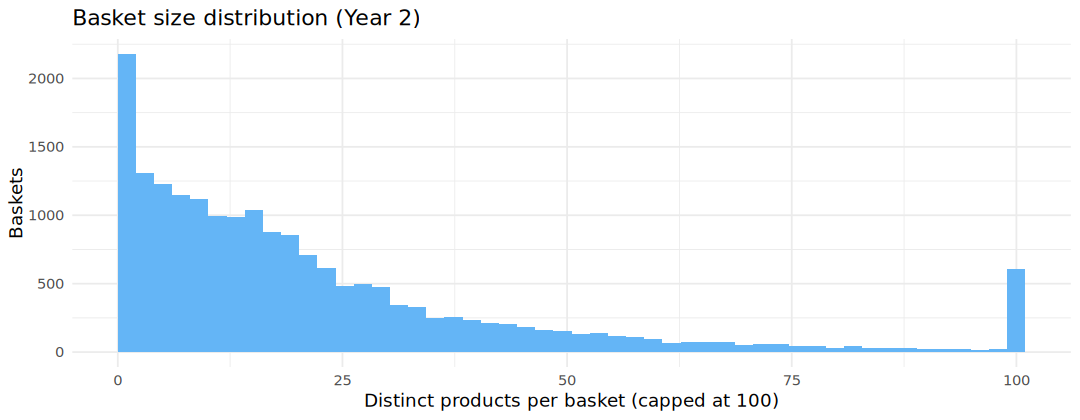

In [3]:
p_size <- ggplot(bsize, aes(pmin(n_items, 100))) +
  geom_histogram(bins = 50, fill = "#64B5F6") +
  labs(x = "Distinct products per basket (capped at 100)", y = "Baskets",
       title = "Basket size distribution (Year 2)") +
  theme_minimal(base_size = 11)
ggsave(file.path(fig, "bq5_basket_size_r.png"), p_size, width = 9, height = 3.5, dpi = 150)
options(repr.plot.width = 9, repr.plot.height = 3.5); p_size

## Frequent itemsets and rules

`arules` stores baskets as a sparse `transactions` object, so no product filtering is needed.
`maxlen = 3` limits rules to three products in total; `minlen = 2` excludes rules with an empty left-hand side.

In [4]:
trans <- as(split(baskets$stock_code, baskets$invoice), "transactions")
cat(sprintf("Transactions: %s baskets x %s products\n", comma(length(trans)), comma(ncol(trans))))

freq <- apriori(trans, parameter = list(supp = MIN_SUPPORT, maxlen = MAX_LEN, target = "frequent itemsets"),
                control = list(verbose = FALSE))
rules_ar <- apriori(trans, parameter = list(supp = MIN_SUPPORT, conf = MIN_CONF, minlen = 2, maxlen = MAX_LEN,
                                            target = "rules"),
                    control = list(verbose = FALSE))

key <- function(x) paste(sort(x, method = "radix"), collapse = " + ")   # C-locale sort, as in Python
lhs_list <- LIST(lhs(rules_ar), decode = TRUE)
rhs_list <- LIST(rhs(rules_ar), decode = TRUE)
q <- quality(rules_ar)

rules <- tibble(
  lhs_codes  = vapply(lhs_list, key, ""),
  rhs_code   = vapply(rhs_list, key, ""),
  n_lhs      = lengths(lhs_list),
  support    = q$support, confidence = q$confidence, lift = q$lift, count = q$count) |>
  mutate(rule_key = paste(lhs_codes, "=>", rhs_code),
         lhs = vapply(lhs_list, function(x) paste(item_name[sort(x, method = "radix")], collapse = " + "), ""),
         rhs = unname(item_name[rhs_code])) |>
  arrange(desc(lift), rule_key)

isz <- size(items(freq))
cat(sprintf("Frequent itemsets: %s (%d single, %d pairs, %d triples)\n",
            comma(length(freq)), sum(isz == 1), sum(isz == 2), sum(isz == 3)))
cat(sprintf("Rules: %s   (1 product on the left: %d, 2 products: %d)\n",
            comma(nrow(rules)), sum(rules$n_lhs == 1), sum(rules$n_lhs == 2)))
cat(sprintf("Lift: median %.1f, max %.1f   Confidence: median %.2f\n",
            median(rules$lift), max(rules$lift), median(rules$confidence)))

Transactions: 18,837 baskets x 3,901 products
Frequent itemsets: 1,933 (814 single, 863 pairs, 256 triples)
Rules: 1,488   (1 product on the left: 731, 2 products: 757)
Lift: median 9.3, max 78.9   Confidence: median 0.51


## Strongest rules

In [5]:
show <- c("lhs", "rhs", "support", "confidence", "lift", "count")
cat("Top 15 rules by lift:\n")
print(as.data.frame(head(rules[, show], 15)), digits = 4)
cat("\nTop 10 rules by support (most common combinations, confidence >= 30%):\n")
print(as.data.frame(head(arrange(rules, desc(support), rule_key)[, show], 10)), digits = 4)

Top 15 rules by lift:
                                          lhs                  rhs support confidence  lift count
1     HERB MARKER THYME + HERB MARKER PARSLEY HERB MARKER ROSEMARY 0.01030     0.9510 78.91   194
2  HERB MARKER ROSEMARY + HERB MARKER PARSLEY    HERB MARKER THYME 0.01030     0.9510 78.91   194
3       HERB MARKER THYME + HERB MARKER BASIL HERB MARKER ROSEMARY 0.01003     0.9497 78.81   189
4    HERB MARKER ROSEMARY + HERB MARKER BASIL    HERB MARKER THYME 0.01003     0.9356 77.64   189
5    HERB MARKER THYME + HERB MARKER ROSEMARY  HERB MARKER PARSLEY 0.01030     0.9238 77.00   194
6                           HERB MARKER THYME HERB MARKER ROSEMARY 0.01115     0.9251 76.77   210
7                        HERB MARKER ROSEMARY    HERB MARKER THYME 0.01115     0.9251 76.77   210
8                           HERB MARKER THYME  HERB MARKER PARSLEY 0.01083     0.8987 74.90   204
9                        HERB MARKER ROSEMARY  HERB MARKER PARSLEY 0.01083     0.8987 74.90   20

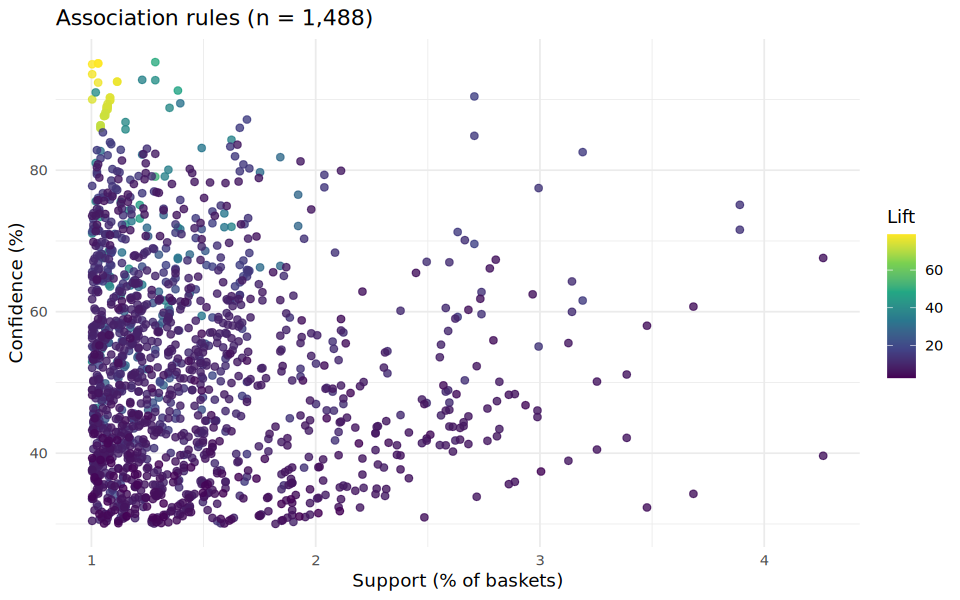

In [6]:
p_sc <- ggplot(rules, aes(support * 100, confidence * 100, colour = lift)) +
  geom_point(size = 1.8, alpha = 0.8) + scale_colour_viridis_c() +
  labs(x = "Support (% of baskets)", y = "Confidence (%)", colour = "Lift",
       title = sprintf("Association rules (n = %s)", comma(nrow(rules)))) +
  theme_minimal(base_size = 11)
ggsave(file.path(fig, "bq5_rules_scatter_r.png"), p_sc, width = 8, height = 5, dpi = 150)
options(repr.plot.width = 8, repr.plot.height = 5); p_sc

## Product pairs: one row per pair

In [7]:
# TRUE where x comes before y in C-locale order (as Python's string comparison)
sort_first <- function(x, y) mapply(function(u, v) sort(c(u, v), method = "radix")[1] == u, x, y)

pair_tbl <- rules |>
  filter(n_lhs == 1) |>
  mutate(a = if_else(sort_first(lhs_codes, rhs_code), lhs_codes, rhs_code),
         b = if_else(sort_first(lhs_codes, rhs_code), rhs_code, lhs_codes)) |>
  group_by(a, b) |>
  summarise(support = first(support), lift = first(lift),
            conf_a_to_b = confidence[lhs_codes == a][1], conf_b_to_a = confidence[lhs_codes == b][1]) |>
  ungroup() |>
  mutate(product_a = unname(item_name[a]), product_b = unname(item_name[b])) |>
  arrange(desc(lift), a, b)
cat(sprintf("Distinct product pairs with at least one rule: %s\n\n", comma(nrow(pair_tbl))))
print(as.data.frame(head(pair_tbl[, c("product_a", "product_b", "support", "conf_a_to_b", "conf_b_to_a", "lift")], 15)),
      digits = 4)

Distinct product pairs with at least one rule: 491

                          product_a                           product_b support conf_a_to_b conf_b_to_a  lift
1                 HERB MARKER THYME                HERB MARKER ROSEMARY 0.01115      0.9251      0.9251 76.77
2                 HERB MARKER THYME                 HERB MARKER PARSLEY 0.01083      0.8987      0.9027 74.90
3              HERB MARKER ROSEMARY                 HERB MARKER PARSLEY 0.01083      0.8987      0.9027 74.90
4               HERB MARKER PARSLEY                    HERB MARKER MINT 0.01072      0.8938      0.8860 73.84
5              HERB MARKER ROSEMARY                   HERB MARKER BASIL 0.01072      0.8899      0.8899 73.84
6               HERB MARKER PARSLEY                   HERB MARKER BASIL 0.01067      0.8894      0.8855 73.80
7              HERB MARKER ROSEMARY                    HERB MARKER MINT 0.01062      0.8811      0.8772 72.79
8                 HERB MARKER THYME                   HERB MARKER BA

## Checks against Python

Rules are matched by their key (stock codes sorted in C-locale order, as in Python), so the comparison does not depend on row order.

In [8]:
py_file <- file.path(root, "reports", "dashboard_data", "basket_rules.csv")
if (file.exists(py_file)) {
  py <- read.csv(py_file, colClasses = c(rule_key = "character"))
  both <- inner_join(rules, py, by = "rule_key", suffix = c("_r", "_py"))
  cat(sprintf("Rules: R %s, Python %s, in both %s\n", comma(nrow(rules)), comma(nrow(py)), comma(nrow(both))))
  cat(sprintf("Only in R: %d   Only in Python: %d\n",
              length(setdiff(rules$rule_key, py$rule_key)), length(setdiff(py$rule_key, rules$rule_key))))
  cat(sprintf("Max difference: support %.1e   confidence %.1e   lift %.1e   count %d\n",
              max(abs(both$support_r - both$support_py)), max(abs(both$confidence_r - both$confidence_py)),
              max(abs(both$lift_r - both$lift_py)), max(abs(both$count_r - both$count_py))))
} else {
  cat("Run 05_market_basket_py.ipynb first to create basket_rules.csv.\n")
}

Rules: R 1,488, Python 1,488, in both 1,488
Only in R: 0   Only in Python: 0
Max difference: support 5.0e-07   confidence 5.0e-07   lift 5.0e-07   count 0
